In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent

sys.path.append(str(PROJECT_ROOT))

In [ ]:
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from transformers import (
    AutoTokenizer,
    AutoModel,
)

from src.config.settings import (
    PROCESSED_DATA_DIR,
    ERISK_FEATURE_ROOT,
)

In [3]:
MODEL_NAME = "microsoft/deberta-v3-base"

MAX_POSTS = 128

MAX_LENGTH = 512

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"

)

print(DEVICE)

cpu


In [ ]:
dataset = pd.read_pickle(

    PROCESSED_DATA_DIR /

    "dataset.pkl"

)

dataset.head()

In [ ]:
# dataset stats
print("Subjects:", len(dataset))

print()

print(dataset.columns)

print()

dataset[

    [

        "label",

        "num_posts",

        "word_count",

    ]

].describe()

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(

    MODEL_NAME

)

print(tokenizer)

In [7]:
# Load model
model = AutoModel.from_pretrained(

    MODEL_NAME

)

model.to(DEVICE)

model.eval()

print(model.config.hidden_size)

768


In [8]:
# Mean pooling func
def mean_pooling(

    model_output,

    attention_mask,

):

    token_embeddings = (

        model_output.last_hidden_state

    )

    mask = (

        attention_mask

        .unsqueeze(-1)

        .expand(token_embeddings.size())

        .float()

    )

    summed = torch.sum(

        token_embeddings * mask,

        dim=1,

    )

    counts = torch.clamp(

        mask.sum(dim=1),

        min=1e-9,

    )

    return summed / counts

In [ ]:
# Inspect one user 
sample = dataset.sample(

    1,

    random_state=42,

).iloc[0]

sample

In [ ]:
# Inspect posts
posts = sample["posts"]

print(

    "Total posts:",

    len(posts),

)

print()

print(

    posts[0][:500]

)

In [11]:
# Keep last 128 posts
posts = posts[-MAX_POSTS:]

print(

    len(posts)

)

128


In [12]:
# Encode one post
encoded = tokenizer(

    posts[0],

    max_length=MAX_LENGTH,

    truncation=True,

    padding="max_length",

    return_tensors="pt",

)

{

    k: v.shape

    for k, v in encoded.items()

}

{'input_ids': torch.Size([1, 512]),
 'token_type_ids': torch.Size([1, 512]),
 'attention_mask': torch.Size([1, 512])}

In [13]:
# Gen one embedding
encoded = {

    k: v.to(DEVICE)

    for k, v in encoded.items()

}

with torch.no_grad():

    output = model(**encoded)

embedding = mean_pooling(

    output,

    encoded["attention_mask"],

)

embedding.shape

torch.Size([1, 768])

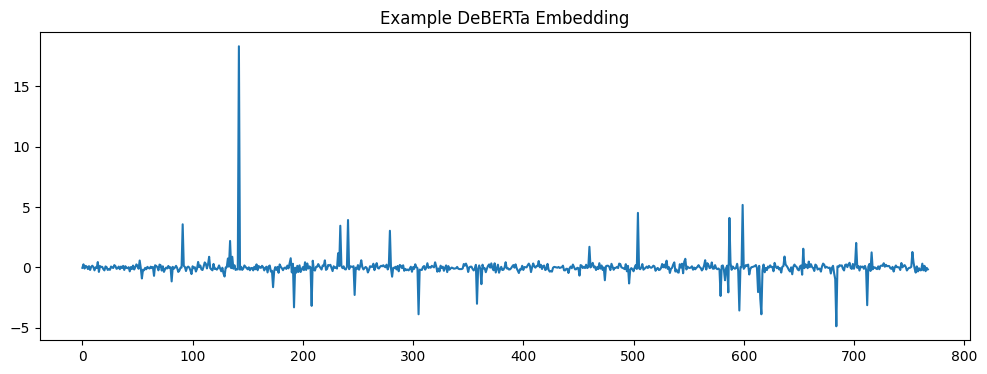

In [14]:
# Visualise one embedding
plt.figure(

    figsize=(12,4)

)

plt.plot(

    embedding

    .cpu()

    .numpy()

    .flatten()

)

plt.title(

    "Example DeBERTa Embedding"

)

plt.show()

In [15]:
# Embed all posts from one user
sequence = []

for post in posts:

    encoded = tokenizer(

        post,

        max_length=MAX_LENGTH,

        truncation=True,

        padding="max_length",

        return_tensors="pt",

    )

    encoded = {

        k: v.to(DEVICE)

        for k, v in encoded.items()

    }

    with torch.no_grad():

        output = model(**encoded)

        emb = mean_pooling(

            output,

            encoded["attention_mask"],

        )

    sequence.append(

        emb

        .squeeze()

        .cpu()

        .numpy()

    )

sequence = np.stack(sequence)

sequence.shape

(128, 768)

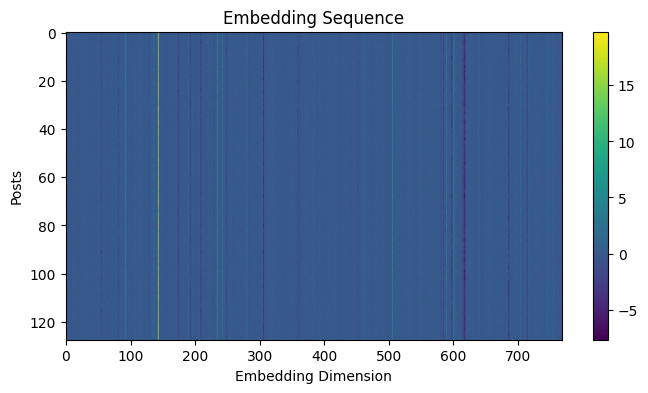

In [16]:
# Inspect sequence
plt.figure(

    figsize=(8,4)

)

plt.imshow(

    sequence,

    aspect="auto",

)

plt.colorbar()

plt.xlabel(

    "Embedding Dimension"

)

plt.ylabel(

    "Posts"

)

plt.title(

    "Embedding Sequence"

)

plt.show()

In [17]:
# NaN check
print(

    np.isnan(sequence).sum()

)

print(

    np.isinf(sequence).sum()

)

0
0


In [ ]:
# Test multiple users
for i in range(5):

    sample = dataset.iloc[i]

    posts = sample["posts"][-MAX_POSTS:]

    print(

        sample["subject_id"],

        len(posts),

    )

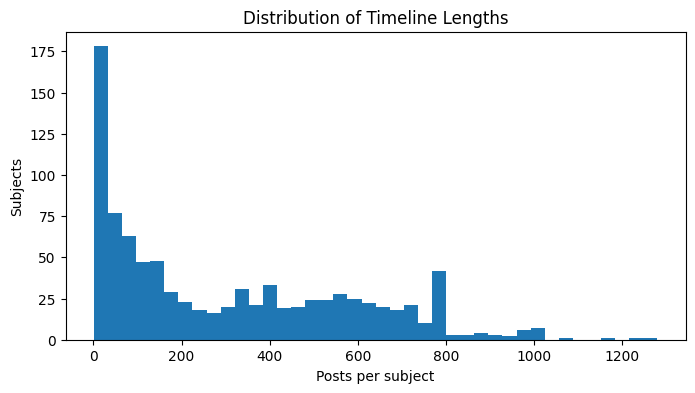

In [ ]:
# Sequence Length distribution (justifies truncate at 128)
lengths = dataset["num_posts"]

plt.figure(figsize=(8,4))

plt.hist(lengths, bins=40)

plt.xlabel("Posts per subject")

plt.ylabel("Subjects")

plt.title("Distribution of Timeline Lengths")

plt.show()

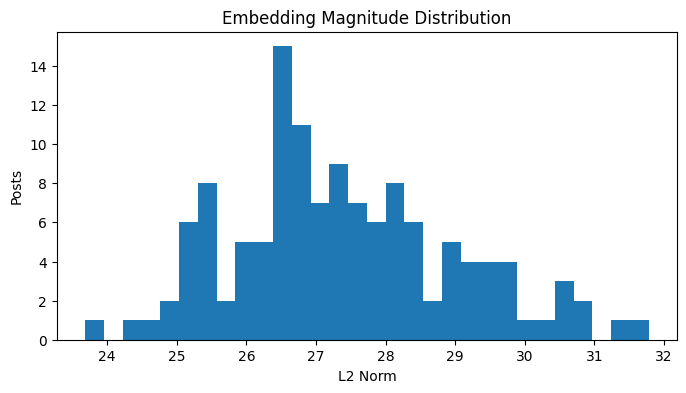

In [20]:
# Embedding norm distribution
norms = np.linalg.norm(sequence, axis=1)

plt.figure(figsize=(8,4))

plt.hist(norms, bins=30)

plt.xlabel("L2 Norm")

plt.ylabel("Posts")

plt.title("Embedding Magnitude Distribution")

plt.show()

In [21]:
import numpy as np

print("Embedding dtype")

print(sequence.dtype)

print()

print("Mean")

print(sequence.mean())

print()

print("Std")

print(sequence.std())

print()

print("Min")

print(sequence.min())

print()

print("Max")

print(sequence.max())

print()

print("NaNs")

print(np.isnan(sequence).sum())

print()

print("Infs")

print(np.isinf(sequence).sum())

Embedding dtype
float32

Mean
0.0024728419

Std
0.9896961

Min
-7.6900926

Max
19.78202

NaNs
0

Infs
0


In [ ]:
from pathlib import Path
import pickle
from collections import Counter

SPLIT_DIR = Path(
    r"C:\Users\<split_path>"
)

for split_name in ["train", "val", "test"]:

    path = SPLIT_DIR / f"{split_name}.pkl"

    print(f"\nChecking: {path}")

    with open(path, "rb") as f:
        data = pickle.load(f)

    print("Number of subjects:", len(data))

    if len(data) > 0 and isinstance(data[0], dict):

        print("Keys:", list(data[0].keys()))

        if "label" in data[0]:

            labels = [
                item["label"]
                for item in data
            ]

            print(
                "Class distribution:",
                Counter(labels)
            )